In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import tqdm as tqdm
import sklearn 
import pickle

from scipy.integrate import simpson
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

In [2]:
with open(r"/data/keeling/a/cstraus2/Phd_research/Apr_2_Oct_Station_events_data_multidf_negdeltas_del_normalized_priorpeaktogether2_delta_perPtot.pkl", "rb") as f:
   Apr_2_Oct_Station_events_dict = pickle.load(f)

In [3]:
#trivariate kde first
def pdf_generation_trifirst(data,bw_scale):

    kde_combined_results =[]
    column_min_max_values = []
    band_widths_tri_vals = []
    
    #iterate through each station's data
    for s, df in data.items():
        #s is the station key in the dictionary and df is specific dataframe 
        #calculate individual kdes
        print('Station:', s)
        #df=df.dropna()

        #calculate trivariate kdes between deltas/ptot, peakP, prior sm 
        P_data = df.loc[:,df.columns.str.contains('Precipitation', regex = True)]
        prior_sm_data = df.loc[:,df.columns.str.contains('Prior', regex = True)]
        
        for i_P in range (P_data.shape[1]):
            P_data_i = P_data.iloc[:, i_P]
            P_col_label = P_data_i.name
            if 'Ptot' in P_col_label: #don't calc for delta/ptot with total P, so change delta cols pulled
                deltas_data = f.loc[:,df.columns.str.contains('Delta') & 
                                        ~df.columns.str.contains('Ptot')]
            else:
                deltas_data = df.loc[:,df.columns.str.contains('Delta', regex = True)]
            for i_sm in range(prior_sm_data.shape[1]):
                prior_sm_data_i = prior_sm_data.iloc[:,i_sm]
                prior_sm_col_label = prior_sm_data_i.name
                for j_Ptot in range(deltas_data.shape[1]):
                    deltas_Ptot_j = deltas_data.iloc[:, j_Ptot]
                    deltas_Ptot_col_label = deltas_Ptot_j.name
                    multi_data = np.vstack([
                        P_data_i.values, prior_sm_data_i.values, deltas_Ptot_j.values
                                        ])
                    tri_kde = stats.gaussian_kde(multi_data, bw_method = 'scott')
                    tri_kde.set_bandwidth(bw_method = tri_kde.scotts_factor() * bw_scale)
                    tri_kde_bw_x = tri_kde.factor * np.sqrt(tri_kde.covariance[0,0])
                    tri_kde_bw_y = tri_kde.factor * np.sqrt(tri_kde.covariance[1,1])
                    tri_kde_bw_z = tri_kde.factor * np.sqrt(tri_kde.covariance[2,2])
                    tri_bw = [tri_kde_bw_x, tri_kde_bw_y, tri_kde_bw_z]
                    trivar_label = f'trivar_kde_{P_col_label}_{prior_sm_col_label}_{deltas_Ptot_col_label}'
                    kde_combined_results.append((s, trivar_label, tri_kde, 'trivariate'))
                    band_widths_tri_vals.append((s, tri_bw, trivar_label))


        #iterate through each column in the station's data
        for col in df.columns:
            #print('column', df[col])
            #print('nan?',df[col].isna().sum())
            #print('inf?',np.isinf(df[col]).sum())
            col_min = np.round(df[col].min(), decimals=2)
            col_max = np.round(df[col].max(), decimals=2)
            column_min_max_values.append((s, col, col_min, col_max))

            
    #check shape of combined dataframe
    #for i, item in enumerate(kde_combined_results):
    #    print(f"Item {i}: length = {len(item)}, content = {item}")

    #convert results into a multiIndex df
    multi_kde_df = pd.DataFrame(kde_combined_results, columns = ['Station', 'Variable', 'KDE_Object', 
                                                                 'Type'])
    multi_kde_df.set_index(['Station', 'Variable', 'Type'], inplace = True)

    min_max_df = pd.DataFrame(column_min_max_values, columns=['Station', 'Variable', 'Min', 'Max'])
    min_max_df.set_index(['Station', 'Variable'], inplace=True)
    
    band_widths_tri_df = pd.DataFrame(band_widths_tri_vals, columns = ['Station', 'bandwidth', 
                                                                       'Variable'])
    
    return multi_kde_df, min_max_df, band_widths_tri_df


In [88]:
#for band width scale, <1 shrinks the bandwidth >1 widens it causing more smoothing

Apr_2_Oct_multi_station_kdes, Apr_2_Oct_multi_station_min_max_df, Apr_2_Oct_multi_station_trivar_bw = pdf_generation_trifirst(Apr_2_Oct_Station_events_dict, bw_scale = 0.75) 

Station: bbc
Station: brw
Station: bvl
Station: cmi
Station: dek
Station: dxs
Station: fai
Station: fre
Station: frm
Station: icc
Station: llc
Station: mon
Station: oln
Station: orr
Station: rnd
Station: sfm
Station: siu
Station: sni
Station: stc
Station: ste


Plot precip, soil moisture and deltas 

In [91]:
stations = 'cmi' #Apr_2_Oct_multi_station_kdes.index.get_level_values('Station').unique()
all_station_ind_data = {}
for n in range(1):
    s= 'cmi'
    resolution_num = 51
    n_bw = 60
    var_bw = Apr_2_Oct_multi_station_trivar_bw

    station_kde_Series = Apr_2_Oct_multi_station_kdes['KDE_Object'][s]
      
    all_station_ind_data[s] = {}  
       
    station_cols_min_vals =  Apr_2_Oct_multi_station_min_max_df.Min.loc[s]
    station_cols_max_vals =  Apr_2_Oct_multi_station_min_max_df.Max.loc[s]
    keep_vars = station_cols_min_vals.index.str.contains('Precipitation|Prior|Delta', regex = True)
    filtered_min_vals = station_cols_min_vals[keep_vars]
    filtered_max_vals = station_cols_max_vals[keep_vars]

    if filtered_min_vals.empty or filtered_max_vals.empty:
        print(f"⚠️ No valid min/max values for {s}")
                
    for (tri_label, trivar_kde_obj) in station_kde_Series.items():
        #print(f"Processing tri KDE for {tri_label}")
            tri_kde_name = tri_label[0].replace("trivar_kde_", "")
            delta_var_label = tri_kde_name[tri_kde_name.find('Delta'):]
            prior_var_label = tri_kde_name[tri_kde_name.find('Prior'):tri_kde_name.find('_Delta')]
            P_var_label = tri_kde_name[:tri_kde_name.find('_Prior')]
            try:
                x_min = filtered_min_vals[P_var_label]
                x_max = filtered_max_vals[P_var_label]
                y_min = filtered_min_vals[prior_var_label]
                y_max = filtered_max_vals[prior_var_label]
                z_min = filtered_min_vals[delta_var_label]
                z_max = filtered_max_vals[delta_var_label]

            except KeyError:
                print(f"⚠️ Could not find min/max for some variable")
                continue
                    
            x_vals_P = np.linspace(x_min - 0.1, x_max + 0.1, resolution_num) #
            dx = x_vals_P[1]-x_vals_P[0]
                    
            y_vals_prior = np.linspace(y_min - 0.1, y_max + 0.1, resolution_num)#
            dy = y_vals_prior[1]-y_vals_prior[0]

            z_vals_delta = np.linspace(z_min - 0.1, z_max + 0.1, resolution_num)# 
            dz = z_vals_delta[1]-z_vals_delta[0]

            #pair data in meshgrd and flatten to 3xN array for kde
            X_P, Y_priorsm, Z_deltaPtot =np.meshgrid(x_vals_P, y_vals_prior,z_vals_delta, indexing = 'ij')
            positions = np.vstack([X_P.ravel(), Y_priorsm.ravel(), Z_deltaPtot.ravel()])
            densities = np.reshape(trivar_kde_obj(positions), X_P.shape) #(x,y,z) = (P, prior, delta)
            #print('densisities shape', densities.shape)
            #print(densities)

            # Normalize the density (integrate over all grid points (triple integral))
            #triple_integral = simpson(simpson(simpson(densities, dx=dz, axis = 2), dx = dy, axis = 1), dx=dx, axis = 0) #should sum to 1
            D3_pdf = densities #/ triple_integral  # Normalize to get probability distribution

            edge_vals = np.concatenate([
                    D3_pdf[0, :, :].ravel(), D3_pdf[-1, :, :].ravel(),  # Top and bottom edges
                    D3_pdf[:, 0, :].ravel(), D3_pdf[:, -1, :].ravel(),  # Left and right edges
                    D3_pdf[:, :, 0].ravel(), D3_pdf[:, :, -1].ravel()]) # Front and back edges
            max_edge_density = np.max(edge_vals)
            print(f"🔍 Max density on edges of tri PDF between {P_var_label} and {prior_var_label} and {delta_var_label}: {max_edge_density:.2e}")
            if max_edge_density > 1e-5:
                print("⚠️ Significant density near the edge — consider extending x/y/z " \
                "ranges further,  ideally edge range below 1e-5")

            print('dx,dy,dz', (dx,dy,dz))
            print('bin num for tri', resolution_num)

            # Compute joint probabilities using dx * dy integration
            D3_pvals = D3_pdf * dx * dy * dz  # Discretized probability mass function
            
            #individual pdfs
            P_pdf = np.sum(np.sum(D3_pdf, axis = 2), axis =1) * dy * dz
            prior_pdf = np.sum(np.sum(D3_pdf, axis = 2), axis =0) * dx * dz
            delta_pdf = np.sum(np.sum(D3_pdf, axis = 1), axis =0) * dx * dy

            #P_pdf /= np.sum(P_pdf * dx)
            #prior_pdf /= np.sum(prior_pdf * dy)
            #delta_pdf /= np.sum(delta_pdf * dz)

            #calculate ind probabilites
            P_pvals = P_pdf * dx
            prior_pvals = prior_pdf * dy
            delta_pvals = delta_pdf * dz

            if P_var_label not in all_station_ind_data[s]:
                all_station_ind_data[s][P_var_label] = {'pdf': P_pdf, 
                                                        'probabilities': P_pvals, 
                                                        'axis': x_vals_P}

            if prior_var_label not in all_station_ind_data[s]:
                all_station_ind_data[s][prior_var_label] = {'pdf': prior_pdf, 
                                                            'probabilities': prior_pvals, 
                                                            'axis': y_vals_prior}

            if delta_var_label not in all_station_ind_data[s]:
                all_station_ind_data[s][delta_var_label] = {'pdf': delta_pdf, 
                                                            'probabilities': delta_pvals, 
                                                            'axis': z_vals_delta}



🔍 Max density on edges of tri PDF between Avg_Precipitation_rate_in and Prior_sm_10 and Delta_sm_10: 1.54e+01
⚠️ Significant density near the edge — consider extending x/y/z ranges further,  ideally edge range below 1e-5
dx,dy,dz (0.024000000000000007, 0.020199999999999996, 0.024000000000000007)
bin num for tri 51
🔍 Max density on edges of tri PDF between Avg_Precipitation_rate_in and Prior_sm_10 and Delta_sm_10_perPtot: 1.46e+00
⚠️ Significant density near the edge — consider extending x/y/z ranges further,  ideally edge range below 1e-5
dx,dy,dz (0.024000000000000007, 0.020199999999999996, 0.024000000000000007)
bin num for tri 51
🔍 Max density on edges of tri PDF between Avg_Precipitation_rate_in and Prior_sm_10 and Delta_sm_100: 1.02e+01
⚠️ Significant density near the edge — consider extending x/y/z ranges further,  ideally edge range below 1e-5
dx,dy,dz (0.024000000000000007, 0.020199999999999996, 0.024000000000000007)
bin num for tri 51
🔍 Max density on edges of tri PDF between A

In [54]:
all_station_ind_data

{'cmi': {'Avg_Precipitation_rate_in': {'pdf': array([0.06482433, 0.11572902, 0.18348892, 0.26315921, 0.35204838,
          0.45397969, 0.57439775, 0.70910055, 0.83870842, 0.93745296,
          0.9912684 , 1.01027411, 1.02421989, 1.06247401, 1.13342421,
          1.22175882, 1.3061729 , 1.3770819 , 1.43587479, 1.48297032,
          1.51285174, 1.5190633 , 1.50009911, 1.46170953, 1.41572372,
          1.37414902, 1.34121754, 1.31204019, 1.2804709 , 1.24621209,
          1.21223275, 1.17766554, 1.13655713, 1.08311692, 1.01607428,
          0.93825356, 0.85441253, 0.77021516, 0.69079826, 0.61850521,
          0.55267856, 0.49143368, 0.43268596, 0.37541445, 0.32229066,
          0.27923867, 0.24931652, 0.22727025, 0.20210249, 0.16588941,
          0.12028188]),
   'probabilities': array([0.00132242, 0.00236087, 0.00374317, 0.00536845, 0.00718179,
          0.00926119, 0.01171771, 0.01446565, 0.01710965, 0.01912404,
          0.02022188, 0.02060959, 0.02089409, 0.02167447, 0.02312185,
      

In [43]:
all_station_ind_data['cmi'].keys()

dict_keys(['Avg_Precipitation_rate_in', 'Prior_sm_10', 'Delta_sm_10', 'Delta_sm_10_perPtot', 'Delta_sm_100', 'Delta_sm_100_perPtot', 'Prior_sm_100', 'Peak_Precipitation_rate_in', 'Median_Precipitation_rate_in', 'Total_Precipitation_in'])

In [ ]:
color_list = ['red', 'indigo','green', 'blue']
line_styles = ['solid', 'dashed', 'solid', 'dashed']
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

ax[0].plot(x_vals, col_pvals, color=color_list[counter], label=f"{pcol}")
ax[0].axhline(y=0, color ='black', linestyle = '-.', alpha=0.5)

ax[0].set_title(f"KDEs for {s} Precipitation", fontsize=18)
ax[0].set_xlabel('Rainrate (in)', fontsize=14)
ax[0].set_ylabel('Probability', fontsize=14)

ax[0].legend()

ax[1].plot(x_vals, col_pvals, color=color_list[counter], linestyle = line_styles[counter], label=f"{smcol}")
ax[1].axhline(y=0, color ='black', linestyle = '-.', alpha=0.5)
#ax[1].hist(Apr_2_Oct_Station_events_dict[s][smcol],
                   #color=color_list[counter], density=True, bins=20, alpha=0.25)
counter += 1

ax[1].set_title(f"KDEs for {s} Soil Moisture", fontsize=18)
ax[1].set_xlabel('Soil Moisture (wfv)', fontsize=14)
ax[1].set_ylabel('Probability', fontsize=14)
#ax[1].set_ylim(-0.001, 0.002)
ax[1].legend()

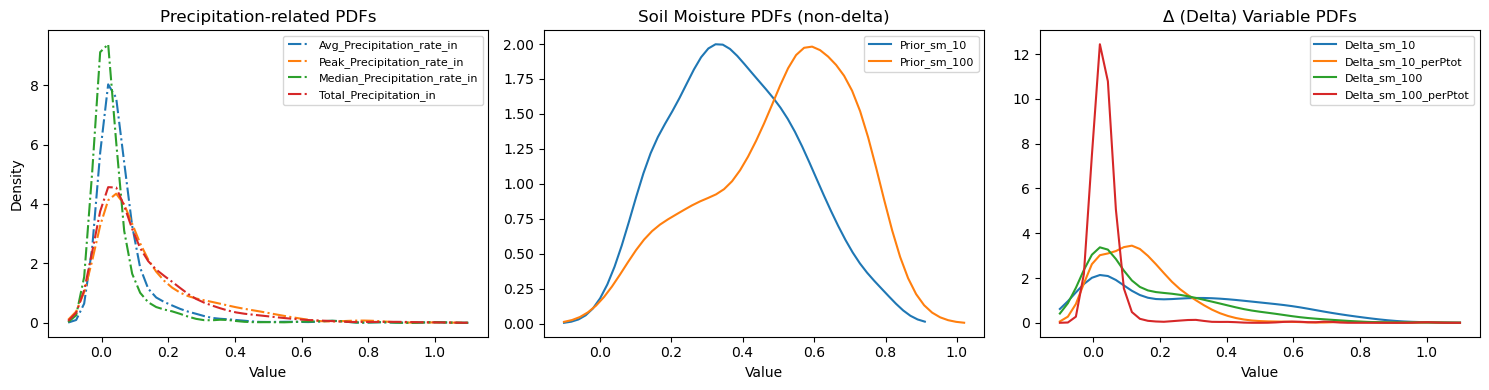

In [92]:
import matplotlib.pyplot as plt

# Example: your single-station data
station_data = all_station_ind_data['cmi']  # for example

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)

# --- 1️⃣ Precipitation variables ---
for var_name, data in station_data.items():
    if "Precipitation" in var_name:
        axes[0].plot(data['axis'], data['pdf'], linestyle = '-.', label=var_name)

axes[0].set_title("Precipitation-related PDFs")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=8)

# --- 2️⃣ Soil moisture (non-delta) variables ---
for var_name, data in station_data.items():
    if "sm" in var_name.lower() and "delta" not in var_name.lower():
        axes[1].plot(data['axis'], data['pdf'], label=var_name)

axes[1].set_title("Soil Moisture PDFs (non-delta)")
axes[1].set_xlabel("Value")
axes[1].legend(fontsize=8)

# --- 3️⃣ Delta variables ---
for var_name, data in station_data.items():
    if "delta" in var_name.lower():
        axes[2].plot(data['axis'], data['pdf'], label=var_name)

axes[2].set_title("Δ (Delta) Variable PDFs")
axes[2].set_xlabel("Value")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()
